# Exploratory data analysis: branch × SKU demand

Questions this notebook answers before any modelling:

1. **How clean is the data?** What the cleaning pipeline found and fixed.
2. **What does demand look like?** Volume concentration, distributions by ABC class.
3. **What patterns must a model capture?** Weekly cycle, annual seasonality by category, holidays, promotions.
4. **How intermittent is demand?** ADI / CV² classification by ABC class: this decides which models are viable.
5. **How different are branches?** Volume, stock-outs and days of supply by branch.

Inputs come from `data/processed/` (run `make data prep` first).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.seasonal import STL

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import get_paths, load_config
from src.metrics import demand_pattern

warnings.simplefilter("ignore", RuntimeWarning)  # all-zero series produce empty-slice warnings
paths = get_paths(load_config())
INK, MUTED, GRID, ACCENT = "#1f2933", "#7b8794", "#e4e7eb", "#0b6e69"
plt.rcParams.update({
    "figure.figsize": (10, 3.6), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=[ACCENT, MUTED, "#c9d1d9"]), "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

w = np.load(paths.processed / "wide.npz")
dates = pd.DatetimeIndex(w["dates"].astype(str))
Y = w["qty_clean"].astype(float)
series = pd.read_parquet(paths.processed / "series.parquet")
status = pd.read_parquet(paths.processed / "inventory_status.parquet")
print(f"{len(series):,} branch x SKU series, {len(dates):,} days ({dates[0].date()} to {dates[-1].date()})")

4,912 branch x SKU series, 1,096 days (2023-10-01 to 2026-09-30)


## 1. Data quality: what cleaning found

In [2]:
dq = pd.read_csv(paths.reports / "data_quality_report.csv")
dq

,check,value
0,raw_rows,5353350
1,exact_duplicates_dropped,2675
2,duplicate_keys_summed,0
3,negative_qty_rows,2663
4,missing_series_days,32867
5,missing_branch_days_full_outage,112
6,outliers_flagged,1222
7,outlier_units_removed,324179
8,bad_adjustments_excluded,230
9,bad_adjustment_units,65842


**Reading the report**

- Exact duplicate rows and negative quantities (customer returns) are removed from the demand signal; returns are kept separately.
- Missing series-days include **full-branch outages**: every SKU at a branch missing on the same day. These are imputed from the same weekday in surrounding weeks, never treated as zero sales.
- Outliers are keying errors at ≥3× a series' own 99th percentile. Checked against the generator's ground truth, the detector has ~99.9% precision and ~76% recall; the misses are small multiples on lumpy series.
- **Stock-out days** (rebuilt on-hand ≤ 0) are ~4.6% of series-days. Sales on those days understate demand, so they are excluded from training targets and from scoring.
- Bad adjustments (large negative entries exceeding stock on hand) are excluded from the ledger; weekly counts reset any remaining drift.

## 2. Demand concentration and distributions

In [3]:
annual_units = np.nansum(Y[:, -365:], axis=1)
s = series.assign(units=annual_units, value=annual_units * series["unit_cost"])
abc = s.groupby("abc_class").agg(skus=("sku_id", "nunique"), series=("sku_id", "size"),
                                 units=("units", "sum"), value=("value", "sum"))
abc["value_share"] = abc["value"] / abc["value"].sum()
abc["mean_daily_units_per_series"] = abc["units"] / abc["series"] / 365
abc.style.format({"units": "{:,.0f}", "value": "${:,.0f}", "value_share": "{:.1%}",
                  "mean_daily_units_per_series": "{:.2f}"})

,skus,series,units,value,value_share,mean_daily_units_per_series
abc_class,,,,,,
A,56,1183,"3,420,307","$130,384,125",79.9%,7.92
B,62,1201,"2,232,596","$24,662,144",15.1%,5.09
C,182,2528,"1,127,913","$8,237,263",5.0%,1.22


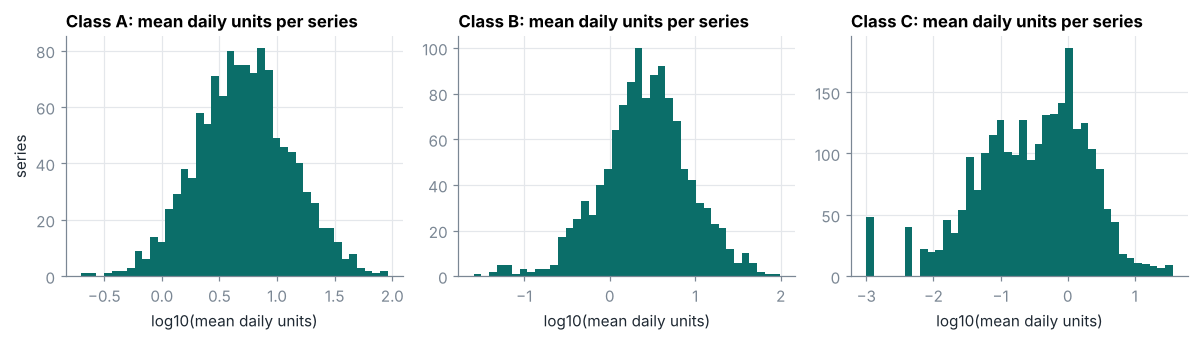

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=False)
for ax, cls in zip(axes, ["A", "B", "C"]):
    m = np.nanmean(Y[(series["abc_class"] == cls).to_numpy(), -365:], axis=1)
    ax.hist(np.log10(m + 1e-3), bins=40, color=ACCENT)
    ax.set_title(f"Class {cls}: mean daily units per series")
    ax.set_xlabel("log10(mean daily units)")
axes[0].set_ylabel("series")
plt.tight_layout()

A items carry ~80% of value with a few units/day per branch; C items mostly sell **well under one unit a day** per branch. A single model family will not fit both ends, which is why selection is done per segment.

## 3. Seasonality, holidays and promotions

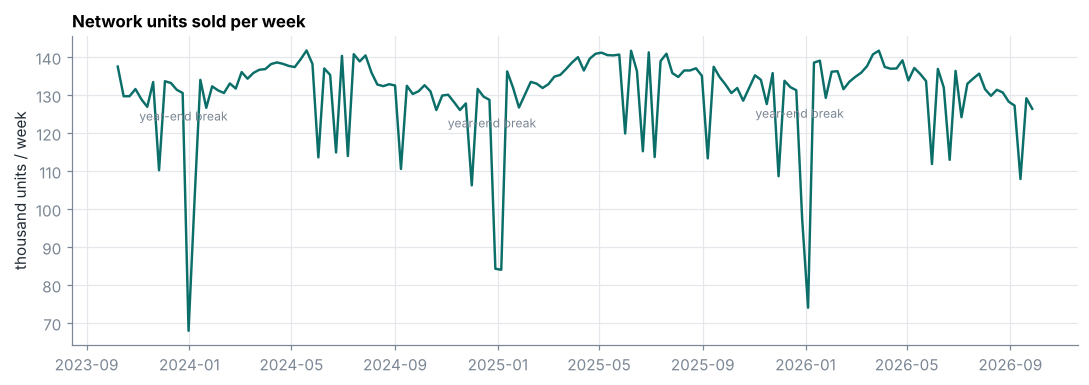

In [5]:
total = pd.Series(np.nansum(Y, axis=0), index=dates)
weekly = total.resample("W-SUN").sum().iloc[1:-1]
fig, ax = plt.subplots()
ax.plot(weekly.index, weekly / 1e3, color=ACCENT, lw=1.6)
ax.set_title("Network units sold per week")
ax.set_ylabel("thousand units / week")
for d in pd.to_datetime(["2023-12-25", "2024-12-25", "2025-12-25"]):
    ax.annotate("year-end break", (d, weekly.asof(d) / 1e3), xytext=(0, -18), textcoords="offset points",
                ha="center", color=MUTED, fontsize=8)
plt.tight_layout()

Share of variance explained by the weekly component: 89%


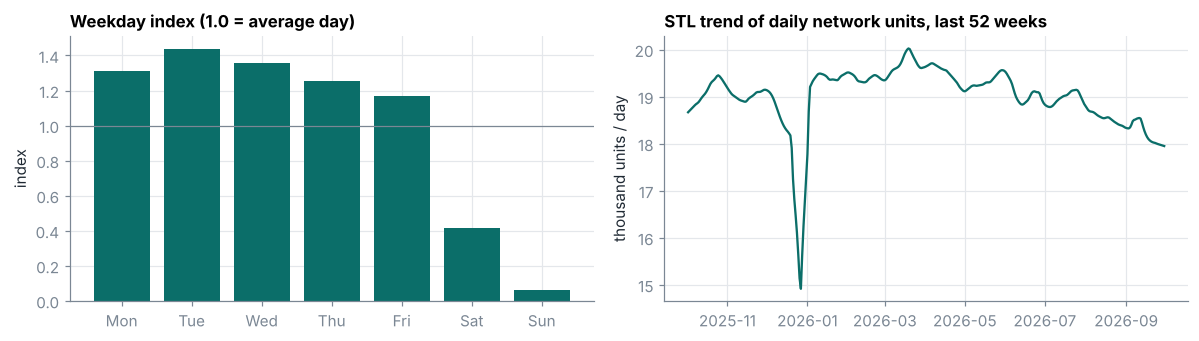

In [6]:
stl = STL(total.iloc[-364:], period=7, robust=True).fit()
dow = total.groupby(total.index.dayofweek).mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow / dow.mean(), color=ACCENT)
axes[0].axhline(1, color=MUTED, lw=0.8)
axes[0].set_title("Weekday index (1.0 = average day)")
axes[0].set_ylabel("index")
axes[1].plot(stl.trend.index, stl.trend / 1e3, color=ACCENT)
axes[1].set_title("STL trend of daily network units, last 52 weeks")
axes[1].set_ylabel("thousand units / day")
plt.tight_layout()
print(f"Share of variance explained by the weekly component: "
      f"{1 - np.var(stl.resid + stl.trend) / np.var(total.iloc[-364:]):.0%}")

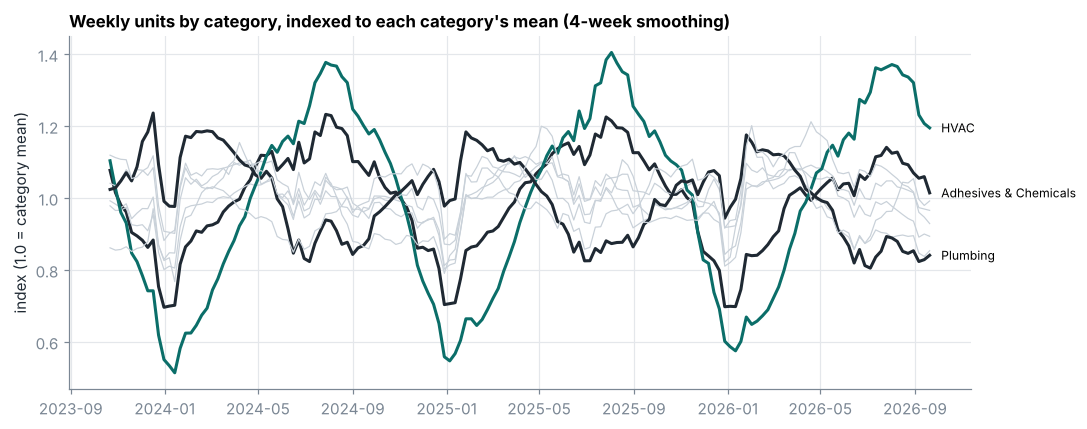

In [7]:
cat_week = (pd.DataFrame(Y.T, index=dates).T.groupby(series["category"].to_numpy()).sum().T
            .resample("W-SUN").sum().iloc[1:-1])
idx = cat_week / cat_week.mean()
fig, ax = plt.subplots(figsize=(10, 4))
for c in idx.columns:
    strong = c in ("HVAC", "Adhesives & Chemicals", "Plumbing")
    ax.plot(idx.index, idx[c].rolling(4, center=True).mean(), lw=2 if strong else 0.8,
            color=ACCENT if c == "HVAC" else (INK if strong else "#c9d1d9"))
    if strong:
        ax.annotate(c, (idx.index[-1], idx[c].rolling(4, center=True).mean().dropna().iloc[-1]),
                    xytext=(4, 0), textcoords="offset points", fontsize=8, va="center")
ax.set_title("Weekly units by category, indexed to each category's mean (4-week smoothing)")
ax.set_ylabel("index (1.0 = category mean)")
plt.tight_layout()

- The **weekly cycle dominates** daily variation: Saturday trades at ~⅓ of a weekday and Sunday is near zero. Every model needs a weekday component.
- **Annual seasonality is category-specific**: HVAC peaks in summer (±45%), Plumbing in winter, Fasteners and Janitorial are flat. The network total looks flat because these offset each other, so a global model needs category × day-of-year interactions, not one network-level seasonal curve.
- Closed holidays and the year-end break show as sharp dips; they are known in advance and are model features.

In [8]:
promo = np.load(paths.processed / "promotions_daily.npz")
pdates = pd.DatetimeIndex(promo["dates"].astype(str))
sku_pos = {s: i for i, s in enumerate(promo["sku_ids"].astype(str))}
rows = series["sku_id"].map(sku_pos).to_numpy()
disc = promo["discount"][rows][:, : len(dates)]
on = disc > 0
base = pd.DataFrame(Y).T.rolling(56, min_periods=28).median().shift(1).T.to_numpy()
with np.errstate(invalid="ignore", divide="ignore"):
    lift = np.nansum(np.where(on, Y, 0)) / np.nansum(np.where(on, base, 0))
print(f"Promotion days: {on.sum():,} series-days on {len(set(series['sku_id'][on.any(axis=1)]))} SKUs; "
      f"units sold vs. trailing 8-week median: {lift:.2f}x")

Promotion days: 112,677 series-days on 107 SKUs; units sold vs. trailing 8-week median: 2.05x


## 4. Intermittency: ADI / CV² by ABC class

col_0,erratic,intermittent,lumpy,no_demand,smooth
abc_class,,,,,
A,52%,14%,23%,0%,10%
B,31%,30%,33%,0%,6%
C,6%,69%,23%,2%,1%


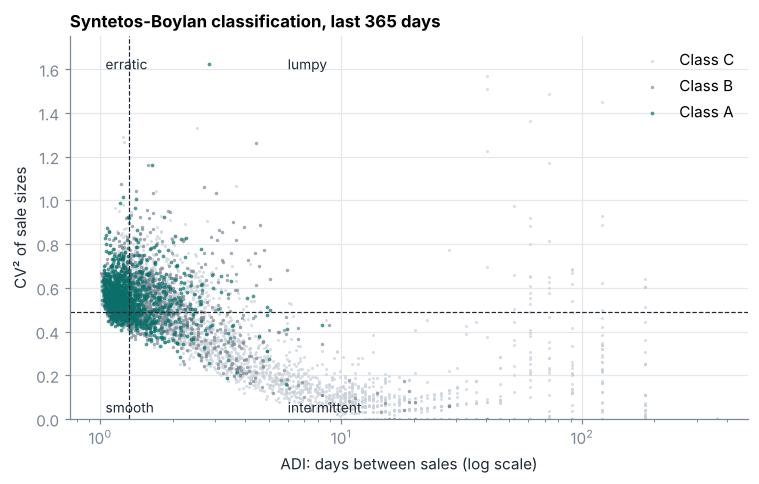

In [9]:
last = Y[:, -365:]
nz = np.nan_to_num(last) > 0
adi = 365 / np.maximum(nz.sum(axis=1), 1)
sizes = np.where(nz, last, np.nan)
cv2 = (np.nanstd(sizes, axis=1) / np.nanmean(sizes, axis=1)) ** 2
pattern = demand_pattern(last)
tab = pd.crosstab(series["abc_class"], pattern, normalize="index")
display(tab.style.format("{:.0%}"))

fig, ax = plt.subplots(figsize=(7, 4.5))
for cls, col, size in [("C", "#c9d1d9", 4), ("B", MUTED, 5), ("A", ACCENT, 6)]:
    m = (series["abc_class"] == cls).to_numpy()
    ax.scatter(adi[m], cv2[m], s=size, color=col, alpha=0.7, label=f"Class {cls}", lw=0)
ax.axvline(1.32, color=INK, lw=0.8, ls="--"); ax.axhline(0.49, color=INK, lw=0.8, ls="--")
ax.set_xscale("log"); ax.set_xlabel("ADI: days between sales (log scale)"); ax.set_ylabel("CV² of sale sizes")
for x, y, t in [(1.05, 0.03, "smooth"), (1.05, 1.6, "erratic"), (6, 0.03, "intermittent"), (6, 1.6, "lumpy")]:
    ax.text(x, y, t, color=INK, fontsize=9)
ax.set_ylim(0, 1.75); ax.legend(frameon=False, loc="upper right")
ax.set_title("Syntetos-Boylan classification, last 365 days")
plt.tight_layout()

Most A-class series are *erratic* rather than smooth: daily B2B order sizes vary a lot even for fast movers. C-class series are mostly *intermittent*, selling on a minority of days. Croston/TSB-style models are the natural statistical candidates there, and WAPE on daily C-class demand will be high for any model; the 28-day totals the inventory policy uses are far more stable.

## 5. Branch comparison

,branch_id,size_tier,series,units,stockout_days,on_hand,daily,stockout_day_rate,days_of_supply
19,B20,Medium,194,"241,778",10900,"7,739",672,15.4%,12
3,B04,Medium,192,"287,126",4977,"14,800",774,7.1%,19
12,B13,Medium,197,"233,893",5095,"12,199",619,7.1%,20
17,B18,Large,205,"438,297",5206,"25,773","1,194",7.0%,22
14,B15,Medium,198,"308,507",4999,"14,513",827,6.9%,18
8,B09,Large,194,"429,397",4886,"20,955","1,148",6.9%,18
22,B23,Small,180,"151,152",4347,"8,200",394,6.6%,21
21,B22,Medium,201,"320,030",3573,"22,642",864,4.9%,26


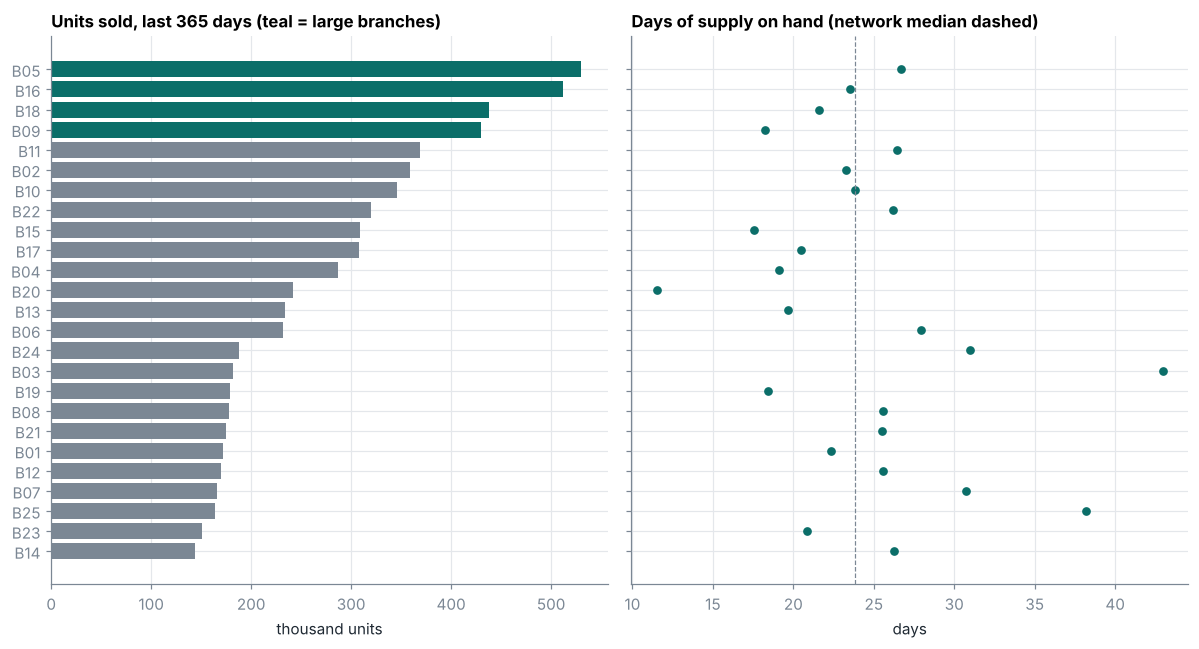

In [10]:
wide_stock = w["is_stockout"][:, -365:]
br = pd.DataFrame({
    "branch_id": series["branch_id"], "size_tier": series["size_tier"],
    "units": np.nansum(Y[:, -365:], axis=1), "stockout_days": wide_stock.sum(axis=1),
    "on_hand": status["on_hand"].to_numpy(),
    "daily": np.nanmean(Y[:, -90:], axis=1),
}).groupby(["branch_id", "size_tier"]).agg(series=("units", "size"), units=("units", "sum"),
                                           stockout_days=("stockout_days", "sum"),
                                           on_hand=("on_hand", "sum"), daily=("daily", "sum")).reset_index()
br["stockout_day_rate"] = br["stockout_days"] / (br["series"] * 365)
br["days_of_supply"] = br["on_hand"] / br["daily"]
br = br.sort_values("units", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
axes[0].barh(br["branch_id"], br["units"] / 1e3, color=[ACCENT if t == "Large" else MUTED for t in br["size_tier"]])
axes[0].set_title("Units sold, last 365 days (teal = large branches)")
axes[0].set_xlabel("thousand units")
axes[1].scatter(br["days_of_supply"], br["branch_id"], color=ACCENT, s=22)
axes[1].axvline(br["days_of_supply"].median(), color=MUTED, ls="--", lw=0.8)
axes[1].set_title("Days of supply on hand (network median dashed)")
axes[1].set_xlabel("days")
plt.tight_layout()
br.sort_values("stockout_day_rate", ascending=False).head(8).style.format(
    {"units": "{:,.0f}", "stockout_day_rate": "{:.1%}", "days_of_supply": "{:.0f}", "on_hand": "{:,.0f}",
     "daily": "{:,.0f}"})

## Takeaways for modelling and rebalancing

1. **Exclude censored days.** About 4.6% of series-days are stock-outs where sales understate demand. Training on them would teach the model to under-forecast exactly the series that need stock.
2. **Weekday + category seasonality + holidays + promotions** are the main structured signals, so they're explicit features in the global LightGBM model.
3. **Segment by ABC × intermittency.** C-class intermittent series get Croston/TSB/SES candidates, and the best model is picked per segment on backtest WAPE.
4. **Branches differ widely in days of supply** for the same demand. That imbalance, not network-level shortage, is the opportunity the rebalancing optimizer targets.